# 多项式回归与欠拟合、过拟合

## 实验说明

本实验的**对照是三次多项式**，即 `myfun`：

$$y = 10 + 5x + 4x^2 + 6x^3$$

训练样本在这条曲线上叠加随机噪声得到。依次训练 4 个模型并对比：

| 模型 | 输入特征 | 作用 |
| --- | --- | --- |
| 一次（线性回归） | `[1, x]` | 先把三次曲线当作一条直线来拟合，作为最简基线，观察**欠拟合** |
| 三次多项式回归 | `[1, x, x², x³]` | 阶数与真实规律一致，观察**适度拟合** |
| 五次多项式回归 | `[1, x, ..., x⁵]` | 阶数偏高，曲线开始被噪声带偏 |
| 九次多项式回归 | `[1, x, ..., x⁹]` | 阶数过高，观察**过拟合** |

这里的“多项式回归”并不是新的模型：`PolynomialFeatures` 负责把 `x` 展开成 `[1, x, x², ...]` 这样的特征矩阵，真正的训练仍然由 `LinearRegression` 完成 —— 模型对**系数**始终是线性的。

### 构造一批样本集

In [1]:
# 实验参照目标函数
def myfun(x):
    '''目标函数
    input:x(float):自变量
    output:函数值'''
    return 10 + 5 * x + 4 * x**2 + 6 * x**3

In [2]:
import numpy as np
np.random.seed(42)
x = np.linspace(-3, 3, 7).reshape(-1, 1)    # 训练样本自变量
x

array([[-3.],
       [-2.],
       [-1.],
       [ 0.],
       [ 1.],
       [ 2.],
       [ 3.]])

In [3]:
# 训练样本标签：y = f(x) + ε，加点噪声
y_true = myfun(x)
noise = np.random.normal(loc=0, scale=30, size=x.shape)
y = y_true + noise

print(f"无噪声真实值 y_true =\n {y_true}\n")
print(f"噪声 ε =\n {noise}\n")
print(f"加噪声后的观测标签 y =\n {y}")
print(y.shape)

无噪声真实值 y_true =
 [[-131.]
 [ -32.]
 [   3.]
 [  10.]
 [  25.]
 [  84.]
 [ 223.]]

噪声 ε =
 [[14.90142459]
 [-4.14792904]
 [19.43065614]
 [45.69089569]
 [-7.02460124]
 [-7.02410871]
 [47.37638447]]

加噪声后的观测标签 y =
 [[-116.09857541]
 [ -36.14792904]
 [  22.43065614]
 [  55.69089569]
 [  17.97539876]
 [  76.97589129]
 [ 270.37638447]]
(7, 1)


In [4]:
# 预测点（测试集）：6 个点，用来计算测试集上的残差均方值
x_p = np.linspace(-2.5, 2.5, 6).reshape(-1, 1)
x_p

array([[-2.5],
       [-1.5],
       [-0.5],
       [ 0.5],
       [ 1.5],
       [ 2.5]])

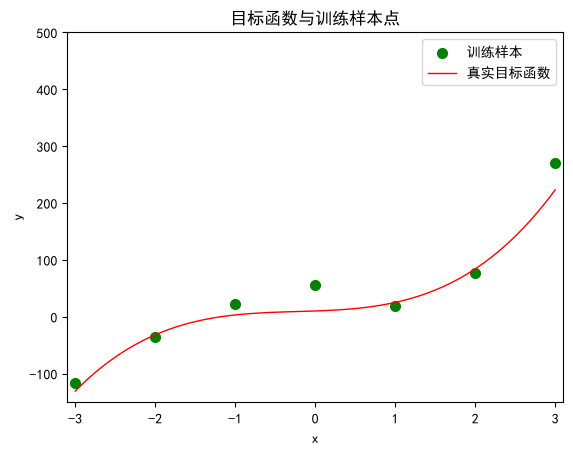

In [5]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 画平滑曲线用的密集点
x_plot = np.linspace(-3, 3, 100).reshape(-1, 1)
y_target = myfun(x_plot)

plt.title(u'目标函数与训练样本点')
plt.scatter(x, y, color='green', linewidth=2, label='训练样本')   # 加噪声的训练样本
plt.plot(x_plot, y_target, color='red', linewidth=1, label='真实目标函数')  # 真实目标函数
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.xlim(-3.1, 3.1)
plt.ylim(-150, 500)
plt.show()

### 一、线性回归模型（1 次，把三次曲线当作直线）

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

model1 = LinearRegression().fit(x, y)

print('--线性回归模型--')
# 训练集残差均方值：模型在训练点 x 上的预测 vs 带噪声的标签 y
print(f'训练集残差均方值（下面绿色训练样本与蓝色预测线）：{mean_squared_error(y, model1.predict(x)):.4f}')
# 测试集残差均方值：模型在预测点 x_p 上的预测 vs 真实函数值 myfun(x_p)
print(f'测试集残差均方值（下面红色真实线与蓝色预测线）：{mean_squared_error(myfun(x_p), model1.predict(x_p)):.4f}') 
print(f'系数：{model1.coef_}')
print(f'截距：{model1.intercept_}')

--线性回归模型--
训练集残差均方值（下面绿色训练样本与蓝色预测线）：2499.0688
测试集残差均方值（下面红色真实线与蓝色预测线）：1459.7617
系数：[[49.32918796]]
截距：[41.60038884]


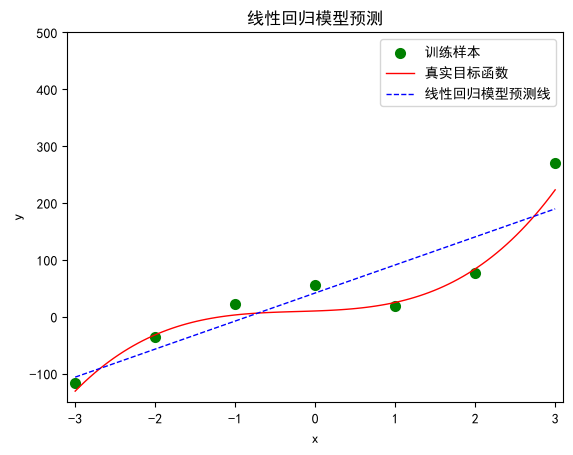

In [7]:
plt.title('线性回归模型预测')
plt.scatter(x, y, color='green', linewidth=2, label='训练样本')
plt.plot(x_plot, y_target, color='red', linewidth=1, label='真实目标函数')
plt.plot(x_plot, model1.predict(x_plot), 'b--', linewidth=1, label='线性回归模型预测线')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.xlim(-3.1, 3.1)
plt.ylim(-150, 500)
plt.show()

### 二、三次多项式模型  
$ \hat{y} = w_0 + w_1 x + w_2 x^2 + w_3 x^3 $ 

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# 把 x 展开成 [1, x, x², x³] 三个多项式特征
poly3 = PolynomialFeatures(degree=3)
x_poly3 = poly3.fit_transform(x)    # 训练集特征展开
x_p_poly3 = poly3.transform(x_p)     # 测试集特征展开

model3 = LinearRegression().fit(x_poly3, y)

print('--三次多项式模型--')
print(f'训练集残差均方值：{mean_squared_error(y, model3.predict(x_poly3)):.4f}')
print(f'测试集残差均方值：{mean_squared_error(myfun(x_p), model3.predict(x_p_poly3)):.4f}')
print(f'系数：{np.round(model3.coef_, 4)}')
print(f'截距：{np.round(model3.intercept_, 4)}')

--三次多项式模型--
训练集残差均方值：350.8605
测试集残差均方值：250.2085
系数：[[ 0.     -4.6887  5.0882  7.7168]]
截距：[21.2477]


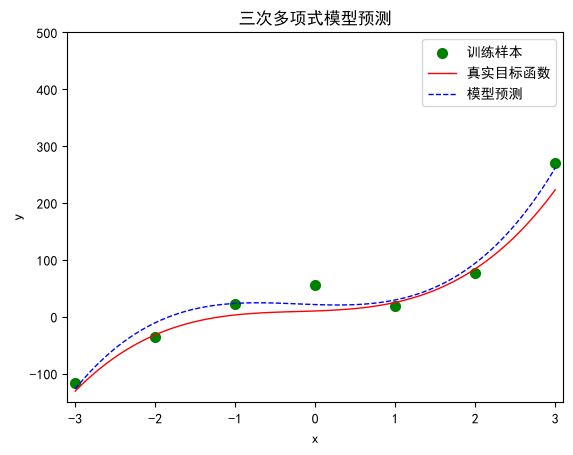

In [9]:
plt.title(u'三次多项式模型预测')
plt.scatter(x, y, color='green', linewidth=2, label='训练样本')
plt.plot(x_plot, y_target, color='red', linewidth=1, label='真实目标函数')
plt.plot(x_plot, model3.predict(poly3.transform(x_plot)), 'b--', linewidth=1, label='模型预测')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.xlim(-3.1, 3.1)
plt.ylim(-150, 500)
plt.show()


### 三、五次多项式模型
$ \hat{y} = w_0 + w_1 x + w_2 x^2 + w_3 x^3 + w_4 x^4 + w_5 x^5 $

In [10]:
poly5 = PolynomialFeatures(degree=5)
x_poly5 = poly5.fit_transform(x)
x_p_poly5 = poly5.transform(x_p)

model5 = LinearRegression().fit(x_poly5, y)

print('--五次多项式模型--')
print(f'训练集残差均方值：{np.round(mean_squared_error(y, model5.predict(x_poly5)), 4)}')
print(f'测试集残差均方值：{np.round(mean_squared_error(myfun(x_p), model5.predict(x_p_poly5)), 4)}')
print(f'系数：{np.round(model5.coef_, 4)}')
print(f'截距：{np.round(model5.intercept_, 4)}')


--五次多项式模型--
训练集残差均方值：55.3653
测试集残差均方值：372.0874
系数：[[  0.     -13.8688 -14.9099  12.009    2.0894  -0.3679]]
截距：[42.7381]


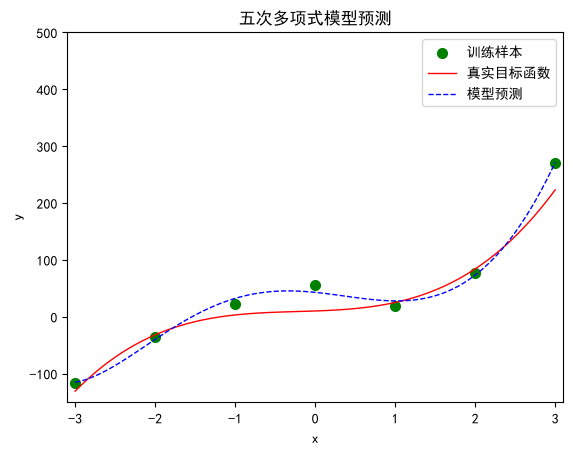

In [ ]:
plt.title('五次多项式模型预测')
plt.scatter(x, y, color='green', linewidth=2, label='训练样本')
plt.plot(x_plot, y_target, color='red', linewidth=1, label='真实目标函数')
plt.plot(x_plot, model5.predict(poly5.transform(x_plot)), 'b--', linewidth=1, label='模型预测')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.xlim(-3.1, 3.1)
plt.ylim(-150, 500)
plt.show()


### 四、九次多项式模型
$ \hat{y} = w_0 + w_1 x + w_2 x^2 + w_3 x^3 + w_4 x^4 + w_5 x^5 + w_6 x^6 + w_7 x^7 + w_8 x^8 + w_9 x^9 $

In [12]:
poly9 = PolynomialFeatures(degree=9)
x_poly9 = poly9.fit_transform(x)
x_p_poly9 = poly9.transform(x_p)

model9 = LinearRegression().fit(x_poly9, y)

print('--九次多项式模型--')
print(f'训练集残差均方值：{np.round(mean_squared_error(y, model9.predict(x_poly9)), 4)}')
print(f'测试集残差均方值：{np.round(mean_squared_error(myfun(x_p), model9.predict(x_p_poly9)), 4)}')
print(f'系数：{np.round(model9.coef_, 4)}')
print(f'截距：{np.round(model9.intercept_, 4)}')


--九次多项式模型--
训练集残差均方值：0.0
测试集残差均方值：11598.3679
系数：[[ -0.      -1.4122 -25.8087  -1.2271 -16.754   -0.5851   7.6829   1.1001
   -0.6081  -0.1033]]
截距：[55.6909]


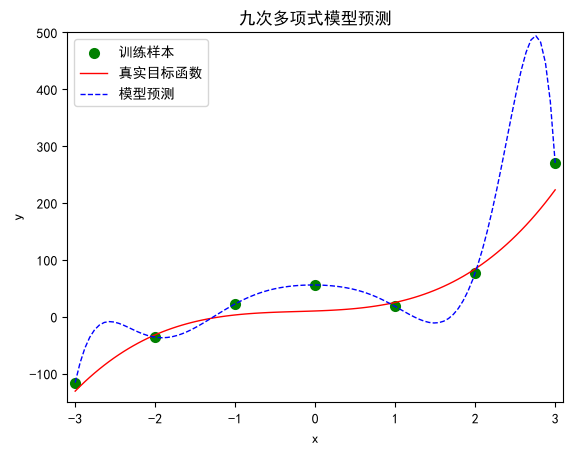

In [13]:
plt.title(u'九次多项式模型预测')
plt.scatter(x, y, color='green', linewidth=2, label='训练样本')
plt.plot(x_plot, y_target, color='red', linewidth=1, label='真实目标函数')
plt.plot(x_plot, model9.predict(poly9.transform(x_plot)), 'b--', linewidth=1, label='模型预测')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.xlim(-3.1, 3.1)
plt.ylim(-150, 500)
plt.show()


### 小结

- 1 次线性回归只能画出一条直线，训练集和测试集误差都大，属于**欠拟合**；
- 3 次多项式与真实规律最为接近（对应上了对照的三次多项式模型），测试集误差最小，属于**适度拟合**；
- 5 次、9 次多项式训练集误差继续下降，但测试集误差明显增大，曲线剧烈抖动、偏离真实函数，属于**过拟合**；
- 4 个模型用的都是 `LinearRegression`，区别只在于 `PolynomialFeatures` 生成了多少阶特征 —— 多项式回归本质仍是线性回归。